# When the tests are green, is the patch right?

**Rahul Morishetti.** Exploratory study, not peer reviewed.

If an AI coding agent's patch keeps the existing tests green, how much does that tell a reviewer?
This notebook reanalyses published runs of one agent harness (mini-SWE-agent v2.0.0) with
13 models on the 500 issues of SWE-bench Verified:
6,500 patches in all. I did not re-run any of them. Hypotheses, metrics and a held-out
split were [written down first](../ANALYSIS_PLAN.md), and departures from that plan are logged there.

## What I found

1. **A green regression run adds little evidence that the issue was fixed.** 23.1%
   of patches with no regression failures still failed the tests written for the issue
   (95% CI 20.0–26.4%). Being green barely moved the pass rate, from 75.4% of all patches to 76.9%.
   The failure figure is an upper bound, because the benchmark runs only part of each project's suite.
2. **The instruction not to edit tests mostly held, and the exceptions need interpreting.**
   31 of 6,400 patches (0.5%) edited a test file anyway, nearly all in files the
   human fix also changed, so this is not evidence of agents gaming tests.
3. **Cheap signals found hard issues, not bad patches.** Static patch signals and agreement between models ranked
   risky patches well overall (AUC 0.74), but comparing patches on the *same issue* they were not
   distinguishable from chance (AUC 0.56, 95% CI 0.44–0.70). The planned hypotheses on this were not supported.

Together these suggest that the missing evidence is about the issue's intent, which neither a regression run nor the
shape of a patch supplies. Testing that directly is the next experiment, and **it has not been run yet**.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

R = json.load(open("../results/results.json"))
X = json.load(open("../results/exploratory.json"))
INK, MUTED, GRID, SURFACE, BLUE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb", "#2a78d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
                     "axes.edgecolor": GRID, "font.size": 10, "figure.dpi": 130})

def clean(ax):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)

## E1: How much does a green regression run overstate correctness?

Terms, from the benchmark's own test lists:

- **Regression green:** the patch applied and no test that passed before the fix now fails (`PASS_TO_PASS`).
- **Fails intent tests:** at least one test written alongside the human fix still fails (`FAIL_TO_PASS`).
- **False acceptance:** the share of regression-green patches that fail intent tests.

1,394 of 6,033 regression-green patches failed intent tests, which is
**23.1%** (95% CI 20.0–26.4%, clustered by issue). The rate varied by model, from
18.6% (claude-4-5-opus-high) to 33.2% (gpt-5-mini). The hypothesis that the rate exceeds zero (H1) is supported.

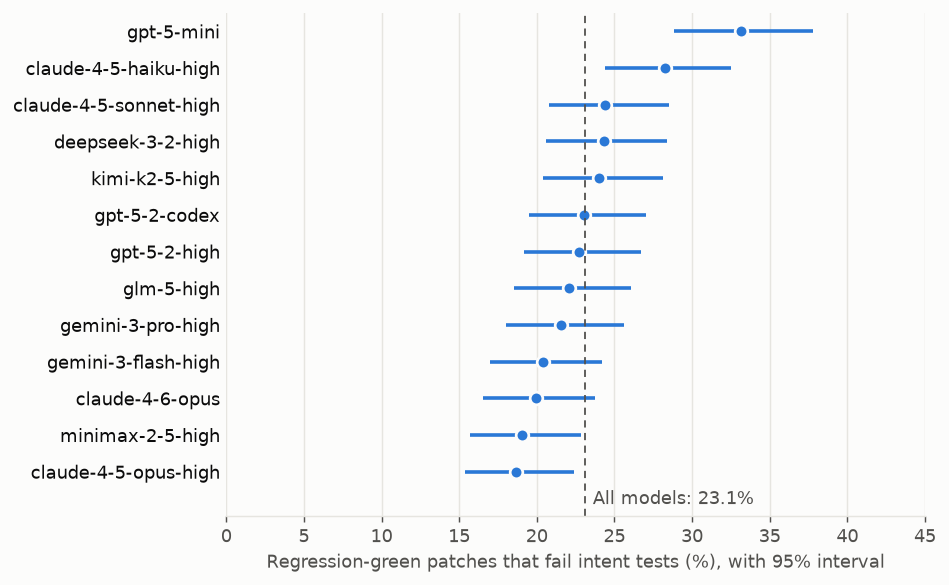

In [2]:
m = pd.DataFrame(R["E1"]["per_model"]).sort_values("false_acceptance")
pooled = R["E1"]["pooled_false_acceptance"]
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.hlines(m.model, 100 * m.ci_low, 100 * m.ci_high, color=BLUE, linewidth=2)
ax.plot(100 * m.false_acceptance, m.model, "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axvline(100 * pooled, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(100 * pooled + 0.5, -0.75, f"All models: {100 * pooled:.1f}%", color=MUTED, va="center")
ax.set_xlim(0, 45)
ax.set_ylim(-1.2, len(m) - 0.5)
ax.set_xlabel("Regression-green patches that fail intent tests (%), with 95% interval")
clean(ax)
fig.tight_layout()
fig.savefig("../results/false_acceptance_by_model.png")
plt.show()

In [3]:
d = pd.DataFrame(R["E1"]["by_difficulty"]).set_index("difficulty").loc[["<15 min fix", "15 min - 1 hour", "1-4 hours", ">4 hours"]]
d.insert(0, "issues", pd.Series(X["issues_per_difficulty"]))
d["false_acceptance"] = (100 * d.false_acceptance).round(1)
display(d.rename(columns={"regression_green": "green patches", "wrong_but_green": "fail intent tests", "false_acceptance": "false acceptance (%)"}))
b = pd.DataFrame(X["false_acceptance_by_regression_tests"]).set_index("regression_tests")
b["false_acceptance"] = (100 * b.false_acceptance).round(1)
display(b.rename(columns={"green_patches": "green patches", "false_acceptance": "false acceptance (%)"}))

,issues,green patches,fail intent tests,false acceptance (%)
difficulty,,,,
<15 min fix,194,2448,307,12.5
15 min - 1 hour,258,3106,799,25.7
1-4 hours,42,440,259,58.9
>4 hours,3,39,29,74.4


,green patches,issues,false acceptance (%)
regression_tests,,,
1-9,776,63,22.2
10-49,2147,174,19.6
50-199,2286,192,24.6
200+,683,57,26.1


**Green and red are not equally informative (exploratory).** 75.4% of all patches passed their intent tests, and 76.9% of green ones did, so a green
result adds little. A red result does say something: only 50.7% of the 367 patches with a regression failure passed. Regression runs are better at raising doubt than at giving confidence.

**The rate rises with the benchmark's difficulty label** (H1b, supported descriptively). The hardest group covers only
3 issues, so it should not be read on its own.

**More regression tests did not visibly help (exploratory).** False acceptance was 22.2% on issues with
1-9 regression tests and 26.1% on those with 200+. This is not causal, since test
counts vary by project, but it fits the idea that regression tests protect old behaviour and say little about new intent.

**The failures are not a handful of outliers.** 219 of 497 issues had at least one such patch.
In 54 issues, every regression-green patch failed. 1,088 of the 1,394 failed all of their intent tests, and
306 failed only some.

**Robustness.** 11 issues have no regression tests, so their patches are green trivially. Excluding them gives 22.6%.

## E2: Do agents touch the tests that are supposed to judge them?

**This experiment could not answer its original question.** I planned to measure how often agents edit tests, then found
that all 13 models received an identical prompt (checked on one issue per model) saying
*"DO NOT MODIFY: Tests, configuration files"* and telling them to diff only the source files they changed. So the rates below
measure **breaches of an explicit instruction**, not natural behaviour. It also explains why no patch adds a test file.

- By the planned path rule, 34 patches edited a test file. 3 of those only change `django/test/testcases.py`, which is framework
  source, so the rule over-counts. **That leaves 31 (0.5%), from 4 of 13 models.**
- 29 of those 31 edit a file that the human fix's test patch also changed. When behaviour changes, old tests often should
  change too, so many of these may be legitimate. **I have not judged them individually, and they are not evidence of cheating.**
- The harness overwrites those 29 files before evaluating, so those edits could not have changed the scores.

The practical point is narrower: a natural-language rule is not a guarantee, even when it is followed 99.5% of the time.
A path check would detect every such edit, but as the second bullet shows, detecting an edit does not tell you whether it was right.

In [4]:
e = pd.DataFrame(X["test_edits"])
e["framework_only"] = e.files.map(lambda fs: all(f.startswith("django/test/") for f in fs))
t = e.groupby("model").agg(planned_rule=("model", "size"), framework_source=("framework_only", "sum"))
t["test_file_edits"] = t.planned_rule - t.framework_source
t["hidden_file_overlap"] = e.groupby("model").hidden_file.sum()
display(t.sort_values("test_file_edits", ascending=False))

,planned_rule,framework_source,test_file_edits,hidden_file_overlap
model,,,,
deepseek-3-2-high,12,1,11,12
claude-4-5-haiku-high,9,0,9,9
gemini-3-pro-high,7,0,7,6
kimi-k2-5-high,4,0,4,3
gpt-5-2-high,1,1,0,1
gpt-5-mini,1,1,0,1


## E3: Can cheap, deterministic signals direct a reviewer's attention?

Among regression-green patches, I tried to rank the ones failing intent tests above the others, using only what is available without
hidden tests: size of the change, files touched, test edits, and how much a patch's files overlap with those of the other 12 models.
A logistic regression was trained on 70% of issues and evaluated once on the remaining 144 (1,772 patches, 362 failing).

The headline metric was fixed in advance: **within-issue AUC**, which asks, for two patches on the *same* issue with one failing, how often the failing one
ranks as riskier. Ordinary AUC can look good simply by detecting that an issue is hard.

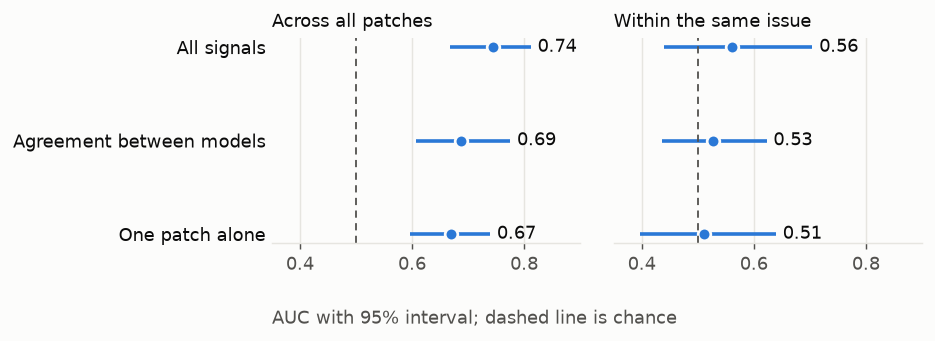

In [5]:
names = {"full_model": "All signals", "consensus_only": "Agreement between models", "single_patch_signals": "One patch alone"}
order = list(names)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6), sharex=True, sharey=True)
for ax, (key, title) in zip(axes, [("auc", "Across all patches"), ("within_auc", "Within the same issue")]):
    vals = [R["E3"][k][key] for k in order]
    cis = [R["E3"][k][key + "_ci"] for k in order]
    labels = [names[k] for k in order]
    ax.hlines(labels, [c[0] for c in cis], [c[1] for c in cis], color=BLUE, linewidth=2)
    ax.plot(vals, labels, "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
    for v, c, l in zip(vals, cis, labels):
        ax.text(c[1] + 0.012, l, f"{v:.2f}", va="center", color=INK)
    ax.axvline(0.5, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlim(0.35, 0.9)
    clean(ax)
fig.supxlabel("AUC with 95% interval; dashed line is chance", fontsize=10, color=MUTED)
fig.tight_layout()
fig.savefig("../results/signals_overall_vs_within_issue.png")
plt.show()

In [6]:
rows = []
for k, n in names.items():
    r = R["E3"][k]
    rows.append({"signals": n, "AUC": round(r["auc"], 3), "within-issue AUC": round(r["within_auc"], 3),
                 "within-issue 95% CI": f"{r['within_auc_ci'][0]:.3f} to {r['within_auc_ci'][1]:.3f}",
                 "failing patches found in top 20% (%)": round(100 * r["recall_top20"], 1)})
display(pd.DataFrame(rows).set_index("signals"))

,AUC,within-issue AUC,within-issue 95% CI,failing patches found in top 20% (%)
signals,,,,
All signals,0.745,0.561,0.439 to 0.705,46.7
Agreement between models,0.687,0.528,0.437 to 0.623,46.4
One patch alone,0.669,0.511,0.396 to 0.640,36.7


**Neither planned hypothesis was supported.** Within-issue AUC was 0.56 for the full model (95% CI 0.44–0.70, H3) and 0.53 for
agreement alone (95% CI 0.44–0.62, H3b). Both intervals include 0.5. They are also wide, so this is **no evidence of an effect, not evidence of no effect.**

**The signals do have a use, but a different one.** Reviewing the riskiest 20% of patches found 46.7% of the failing ones (95% CI 36.7–56.7%), against
20% for random review. Overall AUC held at 0.70–0.80 when each model was left out of training. The gap between overall and within-issue results suggests these signals mostly
identify *which issues are hard*, which can tell a reviewer where to look but not which patch to accept.

Agreement between models is also expensive in practice, since it needs many agents on every issue. Using one patch alone, the signals found 36.7% of failing patches.

## Limits

- **False acceptance is an upper bound.** `PASS_TO_PASS` covers only the test files touched by the human test patch, not the full suite. Real CI might catch more.
- **Intent tests are an imperfect oracle in both directions.** Failing them does not prove a patch is wrong, as they can be tied to the human fix's details, though
  SWE-bench Verified was curated to reduce this. Passing does not prove it right either: [Wang & Pradel](https://arxiv.org/abs/2503.15223) found plausible patches that still behave differently from the human fix.
- **The sample is narrow.** These are open-source Python issues, with one agent harness and one prompt. The test-edit and new-file results in particular depend on that prompt.
- **E2 and E3 changed in meaning.** The prompt also removed all variation in three planned E3 signals, leaving five effective ones.
- **Results are taken as published.** Resolve counts match the leaderboard exactly for 10 of 13 models. The others differ by +2, -1, +5 patches out of 500, and I could not
  explain those beyond 2 missing reports for one model. Reports agree with their own test lists in all 6,498 cases.

## Next: does a test written from the issue alone catch what the green run missed?

E1 to E3 use existing results. The planned experiment E4 is new: generate tests from the issue text at the base commit with no access to any patch, freeze them, then run them on the human
fix and on agent patches. It measures how often they catch these failures, how often they wrongly reject good patches, and whether reading the agent's patch weakens the tests. **Nothing here predicts how that will turn out.**

## Reproduce

```
python -m venv --system-site-packages .venv
.venv/Scripts/python -m pip install scikit-learn datasets pandas
.venv/Scripts/python -I scripts/test_analyze.py
.venv/Scripts/python -I scripts/fetch_cohort.py data/raw
.venv/Scripts/python -I scripts/analyze.py data/raw results
```
The exploratory checks also need one sample trajectory per model in `data/raw/sample_traj/`. This notebook needs only `results/`.